# Telecom Customer Churn Prediction
Supervised ML on a real business problem: predict which customers will churn so the retention team can act *before* they leave.

**Data:** IBM Telco Customer Churn sample dataset — 7,043 customers, 21 columns, 26.5% churn rate.

## 1. Load & clean

In [ ]:
import pandas as pd, numpy as np
df = pd.read_csv("telco_churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(f"{len(df):,} customers | churn rate {df['Churn'].eq('Yes').mean():.1%} | "
      f"blank TotalCharges: {df['TotalCharges'].isna().sum()}")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
df["Churn"] = (df["Churn"] == "Yes").astype(int)

## 2. EDA — where is churn concentrated?
Month-to-month contracts churn at 3× the rate of two-year contracts. Churn is front-loaded: it collapses as tenure grows. And fiber-optic customers without tech support are the hottest segment.

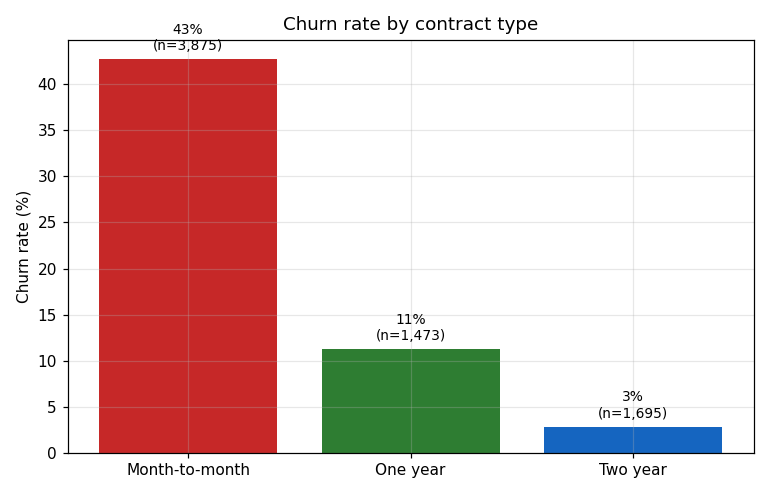

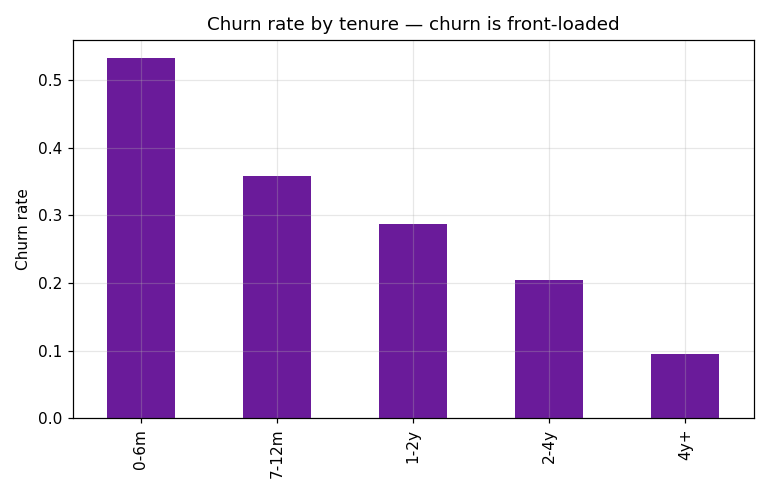

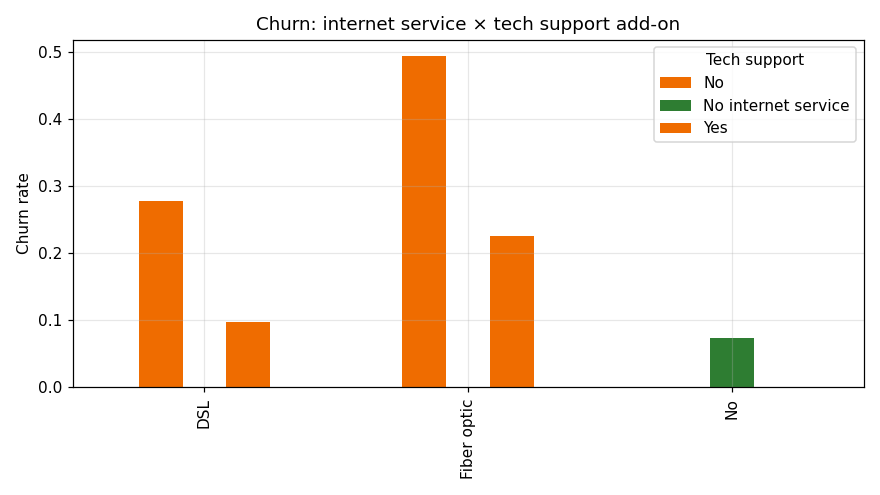

## 3. Modeling setup
Stratified 80/20 split. Three models — logistic regression, random forest, gradient boosting — all with balanced class weights for the 26.5/73.5 imbalance, compared with 5-fold stratified CV on ROC-AUC.

In [ ]:
# Feature matrix and target
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]
print(f"X: {X.shape} | y: {y.shape} | positive rate {y.mean():.1%}")

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split

num = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
cat = [c for c in X.columns if c not in num]
pre = ColumnTransformer([("num", StandardScaler(), num),
                         ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

## 4. Results (test set, n=1,409)
Logistic regression wins on ROC-AUC (0.841) and recall (78.3%) — the two metrics that matter when missing a churner costs more than a false alarm. The simpler model winning is a finding, not a failure.

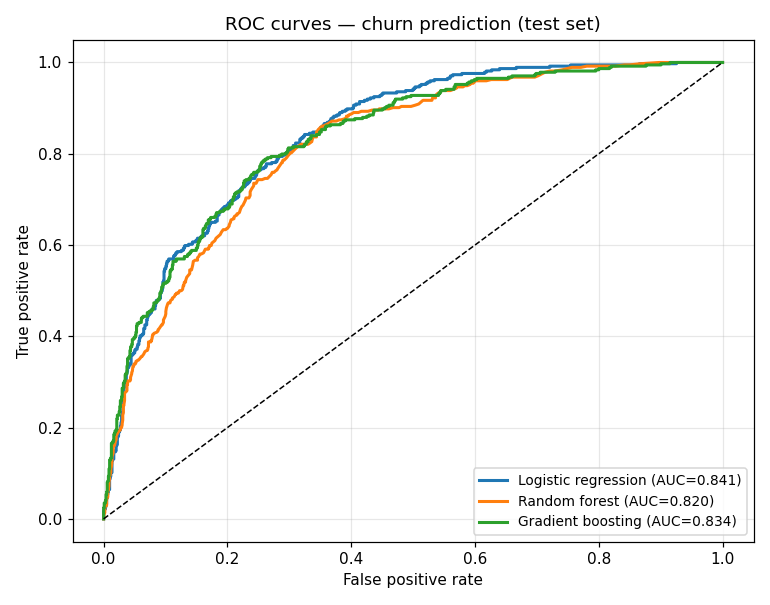

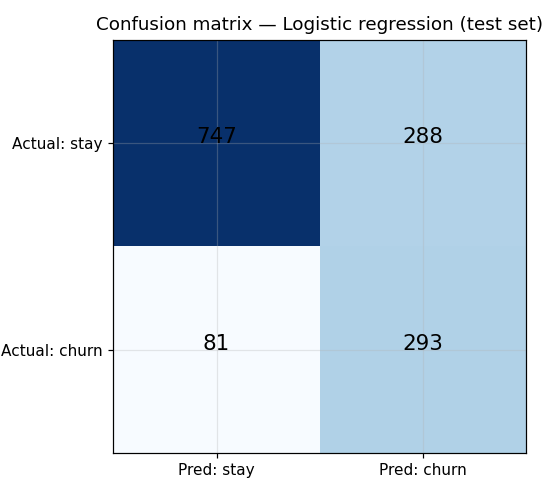

## 5. Threshold tuning
The default 0.5 threshold isn't sacred. For retention, recall matters more than precision — this curve shows exactly what each threshold buys.

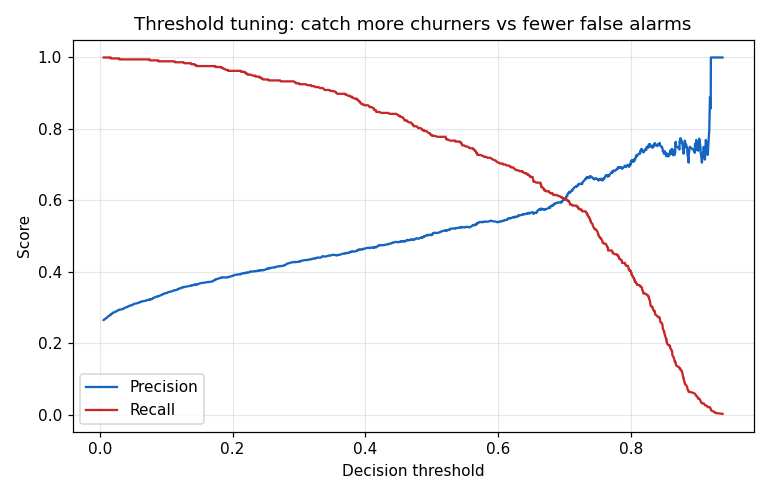

## 6. What drives churn?
Permutation importance on the winning model: tenure dominates, then internet service, contract type, and monthly charges.

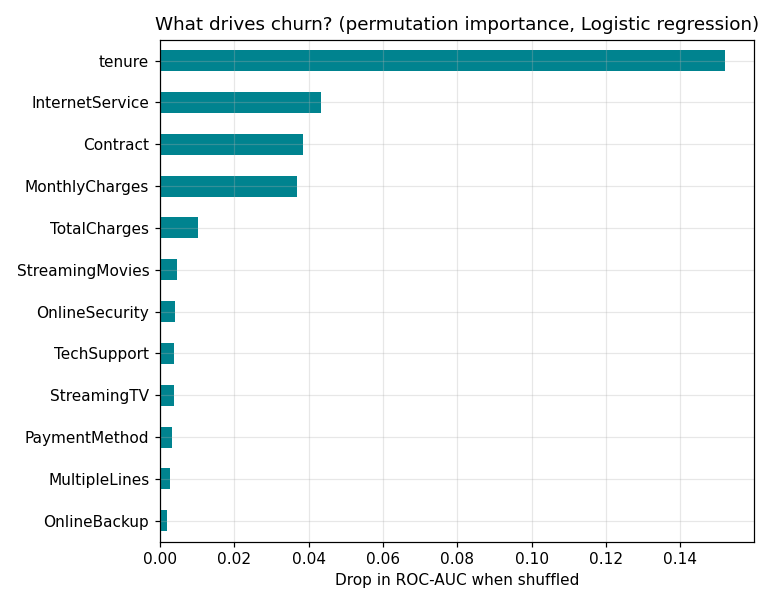

## 7. Business readout
- **High-risk segment (p ≥ 0.7): 1,783 customers (25.3% of base)** churning at **62.6% vs 26.5%** overall — ~$143k/month revenue at risk.
- **Profile:** month-to-month + fiber optic + no tech support.
- **Recommendation:** push contract upgrades and support add-ons at this segment inside the first 6 months; stop reporting churn as one blended number.

Full pipeline in `churn.py`; metrics in `model_metrics.csv`.